(paramfit_pocomc_ntbk)=

# Parameters fit with asteca.Sampler

This is an example of how we can use the [Sampler](asteca.Sampler) class to estimate the fundamental parameters of an observed cluster. It implements Preconditioned Monte Carlo, a Sequential Monte Carlo method that moves a set of particles from the prior to the posterior by slowly increasing the weight given to the likelihood. The implementation is adapted from [pocoMC](https://pocomc.readthedocs.io/), and requires no extra packages (see [Sampler](../sampler_mod) for details). Unlike the ABC approach used in the [Parameters fit with pyABC](paramfit_ntbk) tutorial, it needs an actual (log-)likelihood, which is built from the **ASteCA** [Likelihood](asteca.Likelihood) object.

The user can also combine **ASteCA** with any other package of their choosing, here's a list with many Python-based [MCMC and ABC packages](https://gabriel-p.github.io/pythonMCMC/).

## Loading ASteCA objects

We start by instantiating an [Isochrones](asteca.Isochrones) object with a PARSEC isochrone. This is an example file but you can use whatever isochrone service fits your needs:

In [1]:
import asteca

# Load isochrones
isochs = asteca.Isochrones(
    model='parsec',
    isochs_path="../../_static/isochrones/parsec/",
    mag="Gmag",
    color=("G_BPmag", "G_RPmag"),
    magnitude_effl=6390.7,
    color_effl=(5182.58, 7825.08),
    verbose=2
)


Instantiating isochrones
Model          : PARSEC
N_files        : 1
N_mets         : 5
N_ages         : 13
N_points       : 2000
z    range     : [0.01, 0.03]
loga range     : [7.0, 10.0]
Magnitude      : Gmag
Color          : G_BPmag-G_RPmag
Isochrone object generated


Next we instantiate a [Synthetic](asteca.Synthetic) object, passing the `isochs` object we just created (we are using all defaults for the arguments here):

In [2]:
# Create Synthetic cluster object
synthcl = asteca.Synthetic(isochs, seed=457304, verbose=2)


Instantiating synthetic


(Sampling IMF)


Default params : {'met': 0.0152, 'loga': 8.0, 'alpha': 0.09, 'beta': 0.94, 'Rv': 3.1, 'DR': 0.0, 'Av': 0.2, 'dm': 9.0}
Extinction law : CCMO
Diff reddening : foreground
IMF            : chabrier_2014
Max init mass  : 10000
Gamma dist     : D&K
Random seed    : 457304
Synthetic clusters object generated


Now we load our observed cluster into a [Cluster](asteca.Cluster) object:

In [3]:
import pandas as pd

obs_df = pd.read_csv("../../_static/cluster.csv")

my_cluster = asteca.Cluster(
    ra=obs_df["RA_ICRS"],
    dec=obs_df["DE_ICRS"], 
    mag=obs_df["Gmag"],
    e_mag=obs_df["e_Gmag"],
    color=obs_df["BP-RP"],
    e_color=obs_df["e_BP-RP"],
    verbose=2
)


Instantiating cluster from data
Columns read   : ra, dec, mag, e_mag, color, e_color
N_stars        : 1428
N_nan_phot     : 9
N_clust_min    : 25
N_clust_max    : 2000
Cluster object generated


We assume that the cluster file loaded in `obs_df` is composed of only the most probable members of the cluster. If not, you can refer to the [Membership probabilities](membership) tutorial to learn how to obtain the membership probabilities and select the most probable members.

Finally, we need to calibrate our `synthcl` object and instantiate a [Likelihood](asteca.Likelihood) object, which will be used to quantify how similar our observed cluster is to the generated synthetic clusters. For both operations we need to pass the `my_cluster` object we generated above.

In [4]:
# Calibrate the `synthcl` object
synthcl.calibrate(my_cluster)

# Instantiate the likelihood
likelihood = asteca.Likelihood(my_cluster)


Calibrated observed cluster
N_stars_obs    : 1419
Max magnitude  : 18.99
Error distribution loaded



Likelihood object generated


## Running the sampler

We are now ready to estimate the fundamental parameters. The first step is to define the uniform priors for the parameters that are being estimated, as `(min, max)` values. The parameters that are *not* estimated keep the default values shown when the `synthcl` object was created.

In [5]:
# Ranges for the fitted parameters
priors_dict = {
    "met": (0.01, 0.02),
    "loga": (7.0, 9.5),
    "dm": (8.0, 10.5),
    "Av": (0.0, 2.0),
}

For each set of parameters, the sampler generates a synthetic cluster with the `synthcl` object and compares it with the observed cluster via the `likelihood` object. The log-likelihood is obtained with the `likelihood.log_lkl()` method, which returns the log of the Poisson Likelihood Ratio (see [Likelihood](../likelihood_mod)) relative to its maximum value, so that `0` means a perfect match.

Its `temperature` argument divides the log-likelihood: a value of `1` (the default) gives the posterior of the Poisson likelihood ratio, while values larger than `1` widen the posterior. The synthetic clusters are only an approximation of a real cluster, and for clusters with many members a `temperature` of `1` gives uncertainties that are too small. For clusters with few members, on the other hand, values larger than `1` give uncertainties that are too large and worse fits.

With `temperature="auto"` the value is set with a simple rule that depends on the number of members $N$:

| $N$ | `temperature` |
|---|---|
| $N \leq 150$ | 1 |
| $150 < N \leq 400$ | 2 |
| $N > 400$ | 4 |

This is a **heuristic rule**, not derived from first principles: it was calibrated on simulated clusters (so that the 16th-84th percentile range contains the true values for close to 68% of them) and checked on a set of real clusters. It is a reasonable starting point, but users can pass any other value to suit their own data.

The particles are evaluated in batches with [Likelihood.log_lkl_batch()](asteca.Likelihood.log_lkl_batch). With [numba](https://numba.pydata.org/) installed this removes the Python overhead of each synthetic cluster, and with `parallel=True` the models are also distributed among the CPU cores. **Without numba there is no speedup**, and the results are the same in all cases (see [Log-likelihoods in batches](ref_log_lkl_batch)).

The `n_effective` and `n_active` arguments set the number of particles, here we use their default values (256 and 128). In tests on 100 simulated and 50 real clusters, these values with `n_total=512` took a little more than half the time of twice as many particles, with the same accuracy and uncertainties. Halving them again made the uncertainties too small.

In [6]:
sampler = asteca.Sampler(
    synthcl,
    likelihood,
    priors_dict,
    temperature="auto",
    parallel=True,
    seed=457304,
)


Sampler object generated


The run stops when the posterior is reached and `n_total` effective samples are available. The first run includes the compilation of the numba functions, which are then cached for later sessions:

In [7]:
import time

t0 = time.perf_counter()
sampler.run(n_total=512)
print(f"Run time: {time.perf_counter() - t0:.1f} s")

Sampler run completed
Run time: 2.8 s


## Extracting the results

The `summary()` method returns the median, mean, standard deviation, and 16th and 84th percentiles of each fitted parameter, obtained from the importance weighted posterior samples:

In [8]:
summ = sampler.summary()

print("Parameters estimation:")
print("----------------------")
for k in sampler.names:
    print(
        "{:<5}: {:.3f} +/- {:.3f}  [{:.3f}, {:.3f}]".format(
            k, summ["median"][k], summ["std"][k], summ["p16"][k], summ["p84"][k]
        )
    )

# Medians of the fitted parameters
fit_params = summ["median"]

Parameters estimation:
----------------------
met  : 0.014 +/- 0.002  [0.014, 0.019]
loga : 7.934 +/- 0.096  [7.914, 8.063]
dm   : 8.200 +/- 0.080  [8.091, 8.259]
Av   : 0.505 +/- 0.094  [0.379, 0.556]


The posterior samples can be passed to any plotting package. Here we use [corner](https://corner.readthedocs.io/) to show the 1D and 2D posterior distributions, with the equally weighted (resampled) samples:

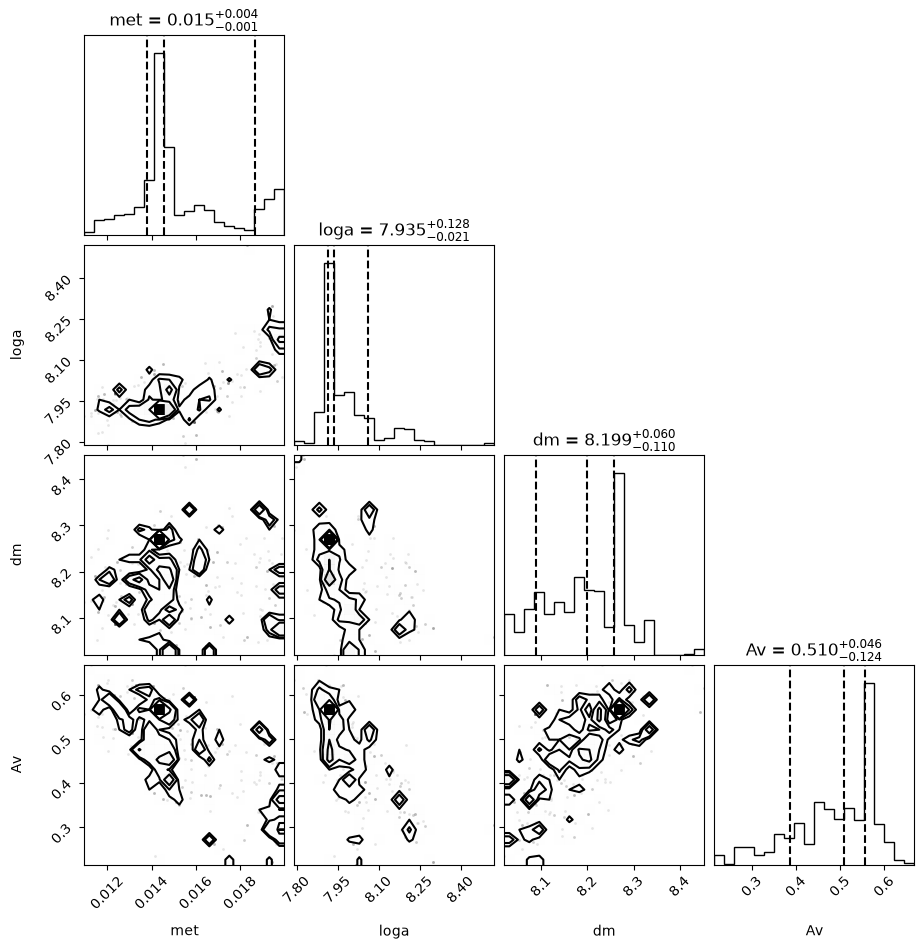

In [9]:
import corner

# Equally weighted posterior samples
samples, _ = sampler.posterior(resample=True)

corner.corner(
    samples,
    labels=sampler.names,
    quantiles=(0.16, 0.5, 0.84),
    show_titles=True,
    title_fmt=".3f",
);

We can generate a CMD comparing our observed cluster with the synthetic cluster generated with the medians, using the medians of the parameter distributions stored in the `fit_params` dictionary:

In [10]:
# Generate the synthetic cluster using these parameters
synth_arr = synthcl.generate(fit_params)

### Goodness of fit

The distance returned by the `likelihood` object is useful to compare synthetic clusters for the *same* observed cluster, but its value can not be compared across clusters (even a perfect model gives a distance larger than zero, by an amount that depends on the number of stars). To assess whether this synthetic cluster is a good representation of the observed cluster we use the [cmd_overlap()](asteca.Likelihood.cmd_overlap) method (see {ref}`Goodness of fit <cmd_overlap>`).

In [11]:
# Distance between the observed cluster and this synthetic cluster
dist = likelihood.dist(synth_arr)
print("Distance       : {:.3f}".format(dist))

# CMD overlap between the observed cluster and this synthetic cluster
D, D_std = likelihood.cmd_overlap(synth_arr)
print("CMD overlap (D): {:.3f} +/- {:.3f}".format(D, D_std))

Distance       : 0.050
CMD overlap (D): 0.045 +/- 0.003


Finally, we can generate a side-by-side CMD plot showing also the theoretical isochrone associated to this synthetic cluster:

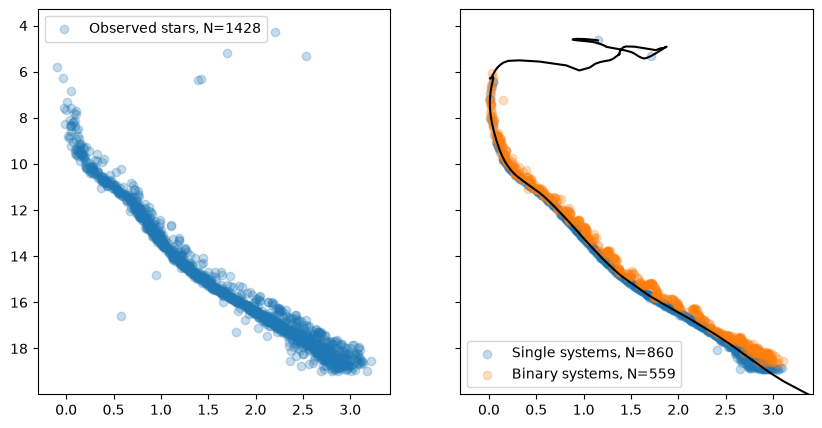

In [12]:
import matplotlib.pyplot as plt
import numpy as np

def cmd_plot(color, mag, label, ax=None):
    """Function to generate a CMD plot"""
    if ax is None:
        ax = plt.subplot(111)
    label = label + f", N={len(mag)}"
    ax.scatter(color, mag, alpha=0.25, label=label)
    ax.legend()

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 5), sharex=True, sharey=True)
# Observed cluster
cmd_plot(my_cluster.color, my_cluster.mag, "Observed stars", ax1)

# Synthetic cluster
# Boolean mask identifying the binary systems
binary_msk = ~np.isnan(synth_arr[-1])
# Extract magnitude and color
mag, color = synth_arr[0], synth_arr[1]
# Plot single systems
cmd_plot(color[~binary_msk], mag[~binary_msk], "Single systems", ax2)
# Plot binary systems
cmd_plot(color[binary_msk], mag[binary_msk], "Binary systems", ax2)

# Get isochrone associated to the synthetic cluster
isoch_arr = synthcl.get_isochrone(fit_params)
# Plot the isochrone
ax2.plot(isoch_arr[1], isoch_arr[0], c="k")

# Same ranges in both plots, defined by the observed cluster (inverted y axis)
ax1.set_xlim(np.nanmin(my_cluster.color) - 0.2, np.nanmax(my_cluster.color) + 0.2)
ax1.set_ylim(np.nanmax(my_cluster.mag) + 1, np.nanmin(my_cluster.mag) - 1);